# Spherical synchrotron and Monte Carlo scattering demo

The spatial grid is 1D in radius. Photon packets are sampled in log energy, propagated in 3D vectors, and scattered in batches.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import nonthradsim.Constants as C
from nonthradsim.grid import Grid
from nonthradsim.particle import Particle, Photon
from nonthradsim.distributions import Powerlaw
from nonthradsim.synchrotron import F, synchrotron
from nonthradsim.mc import run_mc
from nonthradsim.observer import plot_bands, spectrum

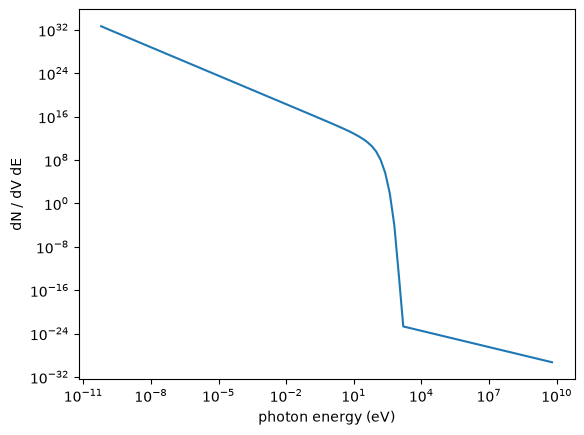

In [2]:
# Build a 1D radial electron profile.
grid = Grid(dimension=1, dx=1e13, n_mesh=101)
particle = Particle(grid, mass=C.me, charge=-1, gm_min=1, gm_max=1e6, n_spectrum=31)
density = 1e10 * np.exp(-(grid.r / grid.radius) ** 2)
Powerlaw(particle, alpha=2.5, gmmin=1, gmmax=1e8, n=density)

photon = Photon(grid, E_min=1e-22, E_max=1e-2, n_spectrum=101)
B = 1e-3 * np.ones(grid.shape)
synchrotron(photon, particle, B, F())

plt.loglog(photon.E * C.erg2eV, photon.value[grid.n_mesh // 2])
plt.xlabel('photon energy (eV)')
plt.ylabel('dN / dV dE')
plt.show()

In [3]:
# Run vectorized batches. Set n_jobs=8 on a machine with enough CPU cores.
escaped = run_mc(
    grid, particle, photon,
    n_particles=1000000,
    batch_size=500,
    n_jobs=5,
    seed=123,
)
print(f"escaped packets: {len(escaped['energy'])}")

escaped packets: 1000000


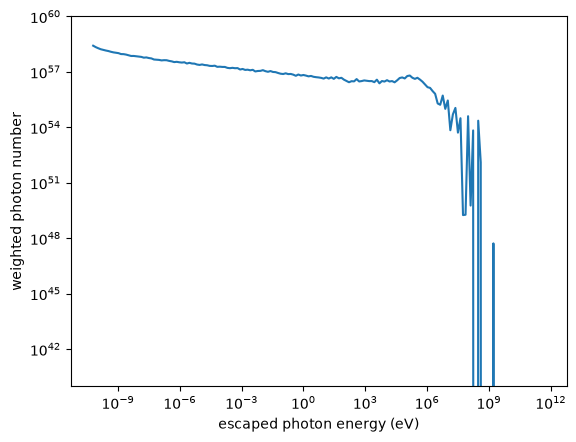

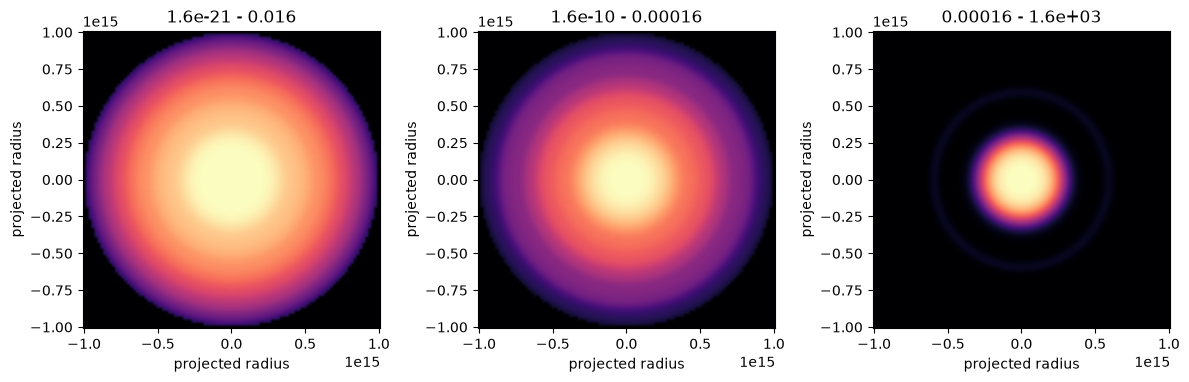

In [4]:
# Accumulate the escaped spectrum and circular sky maps.
from matplotlib import colors as mcolors

energy_edges = np.logspace(-22, 0, 180)
bands = [
    (1e-9 / C.erg2eV, 1e10 / C.erg2eV),
    (1e2 / C.erg2eV, 1e8 / C.erg2eV),
    (1e8 / C.erg2eV, 1e15 / C.erg2eV),
]
escaped_spectrum = spectrum(escaped, energy_edges)
plt.loglog(energy_edges[:-1] * C.erg2eV, escaped_spectrum + 1e-300)
plt.xlabel('escaped photon energy (eV)')
plt.ylabel('weighted photon number')
plt.ylim(1e40,1e60)
# plt.loglog(photon.E * C.erg2eV, photon.value[grid.n_mesh // 2]*1e40)
plt.show()


fig, axes = plot_bands(escaped, grid.radius, energy_edges, bands,image_size=101)#, norm=mcolors.LogNorm())
plt.show()

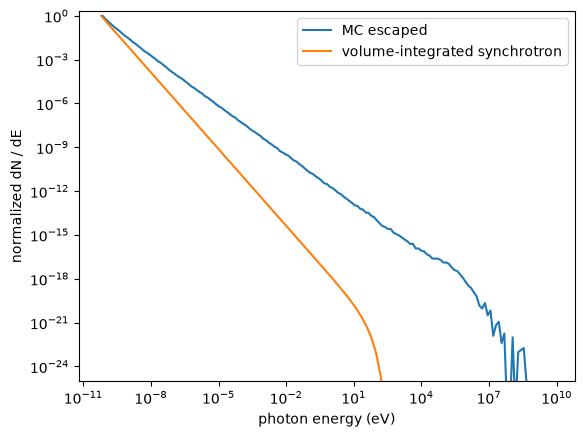

In [5]:
# Compare the volume-integrated synchrotron spectrum with the escaped MC spectrum.
E_center = np.sqrt(energy_edges[:-1] * energy_edges[1:])
dE = np.diff(energy_edges)
escaped_dnde = escaped_spectrum / dE

shell_volume = 4 * np.pi / 3 * (grid.edges[1:]**3 - grid.edges[:-1]**3)
synch_dnde = np.sum(photon.value * shell_volume[:, None], axis=0)

escaped_norm = escaped_dnde / np.max(escaped_dnde)
synch_norm = synch_dnde / np.max(synch_dnde)

mc_mask = escaped_norm > 0
synch_mask = synch_norm > 0
plt.loglog(E_center[mc_mask] * C.erg2eV, escaped_norm[mc_mask], label='MC escaped')
plt.loglog(photon.E[synch_mask] * C.erg2eV, synch_norm[synch_mask], label='volume-integrated synchrotron')
plt.xlabel('photon energy (eV)')
plt.ylabel('normalized dN / dE')
plt.ylim(1e-25, 2)
plt.legend()
plt.show()

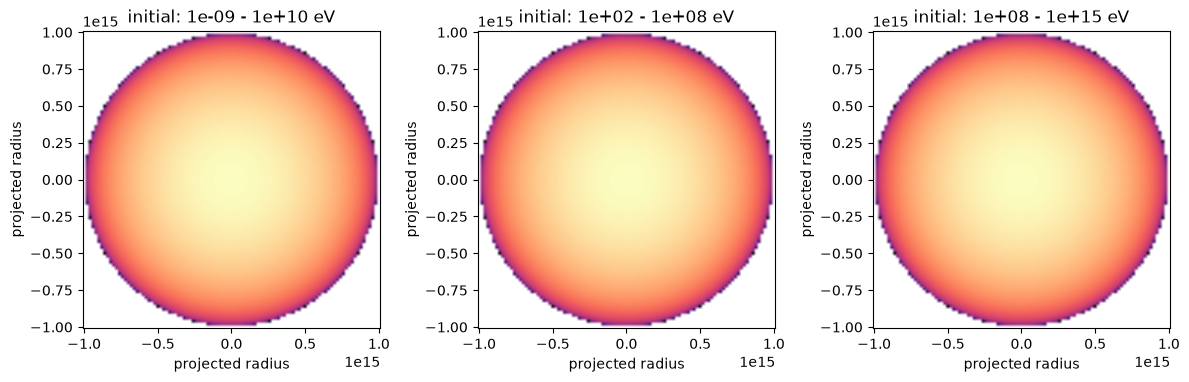

In [6]:
# Project the initial spherical synchrotron field along the line of sight.
# This is a deterministic reference image, before MC transport.
r_centers = 0.5 * (grid.edges[:-1] + grid.edges[1:])
dE_photon = np.gradient(photon.E)
image_size = 101
line_of_sight_points = 1200
axis = np.linspace(-grid.radius, grid.radius, image_size)
xx, yy = np.meshgrid(axis, axis)
impact_parameter = np.sqrt(xx**2 + yy**2)
z_axis = np.linspace(-grid.radius, grid.radius, line_of_sight_points)

fig, axes = plt.subplots(1, len(bands), figsize=(4 * len(bands), 4), squeeze=False)
for i, band in enumerate(bands):
    energy_mask = (photon.E >= band[0]) & (photon.E <= band[1])
    radial_field = np.sum(
        photon.value[:, energy_mask] * dE_photon[energy_mask][None, :],
        axis=1,
    )
    radius_los = np.sqrt(impact_parameter[..., None]**2 + z_axis[None, None, :]**2)
    field_los = np.interp(
        radius_los.ravel(),
        r_centers,
        radial_field,
        left=radial_field[0],
        right=0,
    ).reshape(radius_los.shape)
    field_los[radius_los > grid.radius] = 0
    projected = np.trapezoid(field_los, z_axis, axis=-1)
    projected[impact_parameter > grid.radius] = 0
    positive = projected[projected > 0]
    image_norm = mcolors.LogNorm(vmin=positive.min(), vmax=positive.max()) if positive.size else None
    axes[0, i].imshow(
        projected,
        origin='lower',
        extent=(axis[0], axis[-1], axis[0], axis[-1]),
        cmap='magma',
        norm=image_norm,
        interpolation='bilinear',
    )
    axes[0, i].set_title(f'initial: {band[0] * C.erg2eV:.2g} - {band[1] * C.erg2eV:.2g} eV')
    axes[0, i].set_xlabel('projected radius')
    axes[0, i].set_ylabel('projected radius')
fig.tight_layout()
plt.show()

In [7]:
# Print the fraction of escaped photons that experienced at least one real scattering.
scattered = escaped['n_scatter'] > 0
packet_fraction = np.mean(scattered)
weighted_fraction = np.sum(escaped['weight'][scattered]) / np.sum(escaped['weight'])
print(f' scattered packets: {scattered.sum()} / {scattered.size}')
print(f'packet scattering fraction: {packet_fraction:.6e}')
print(f'weighted scattering fraction: {weighted_fraction:.6e}')

 scattered packets: 670661 / 1000000
packet scattering fraction: 6.706610e-01
weighted scattering fraction: 8.176283e-01


no-scatter packets: 100000
no-scatter real events: 0


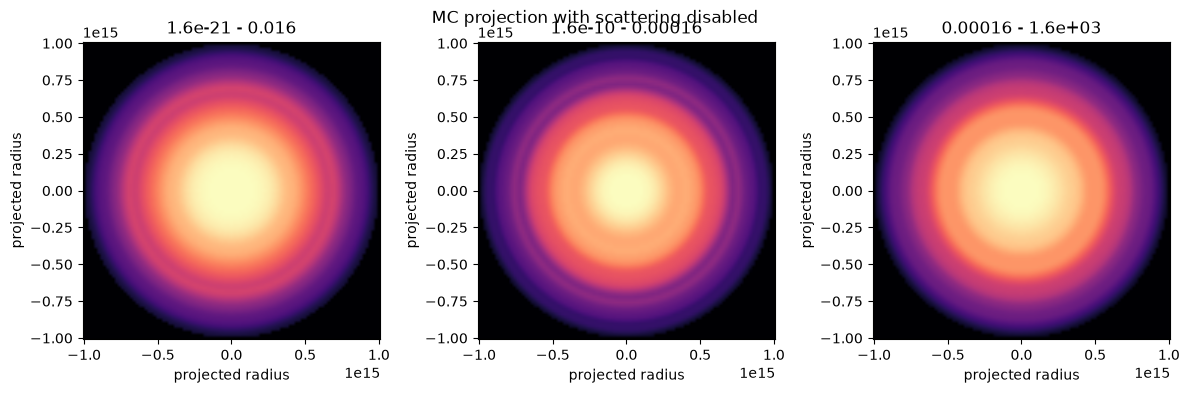

In [8]:
# Diagnostic 1: keep the synchrotron photon field fixed and turn off scattering.
particle_zero = Particle(grid, mass=C.me, charge=-1, gm_min=1, gm_max=1e6, n_spectrum=31)
particle_zero.value[:] = 0
escaped_no_scatter = run_mc(
    grid, particle_zero, photon,
    n_particles=100000,
    batch_size=1000,
    n_jobs=5,
    seed=321,
)
print('no-scatter packets:', len(escaped_no_scatter['energy']))
print('no-scatter real events:', escaped_no_scatter['n_scatter'].sum())
fig, axes = plot_bands(
    escaped_no_scatter, grid.radius, energy_edges, bands,
    image_size=101, radial_bins=64, kernel_width=2,
)
fig.suptitle('MC projection with scattering disabled')
plt.show()

real scattering events: 4782830


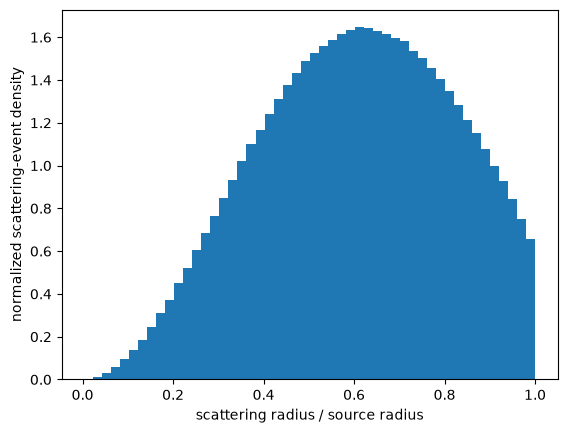

In [9]:
# Diagnostic 2: inspect where real scattering events occur.
scatter_radius = escaped['scatter_radius']
print('real scattering events:', scatter_radius.size)
plt.hist(scatter_radius / grid.radius, bins=50, density=True)
plt.xlabel('scattering radius / source radius')
plt.ylabel('normalized scattering-event density')
plt.show()

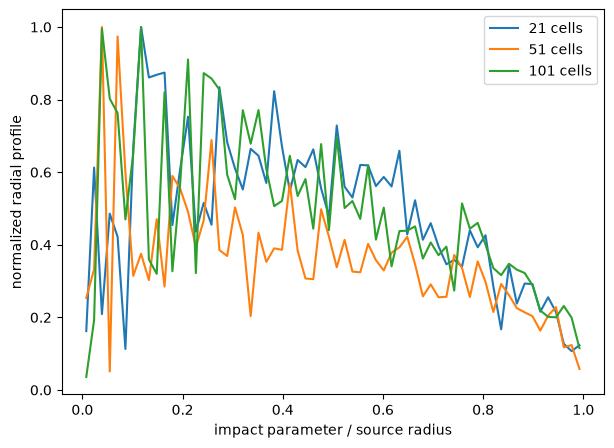

In [10]:
# Diagnostic 3: compare radial resolution while keeping the physical radius fixed.
def build_model(n_mesh):
    test_grid = Grid(dimension=1, dx=grid.radius / n_mesh, n_mesh=n_mesh)
    test_particle = Particle(test_grid, mass=C.me, charge=-1, gm_min=1, gm_max=1e6, n_spectrum=31)
    test_density = 1e10 * np.exp(-(test_grid.r / test_grid.radius) ** 2)
    Powerlaw(test_particle, alpha=2.5, gmmin=1, gmmax=1e8, n=test_density)
    test_photon = Photon(test_grid, E_min=1e-22, E_max=1e-2, n_spectrum=101)
    synchrotron(test_photon, test_particle, 1e-3 * np.ones(test_grid.shape), F())
    return test_grid, test_particle, test_photon

grid_results = {}
for n_mesh in [21, 51, 101]:
    test_grid, test_particle, test_photon = build_model(n_mesh)
    grid_results[n_mesh] = run_mc(
        test_grid, test_particle, test_photon,
        n_particles=30000, batch_size=1000, n_jobs=5, seed=100 + n_mesh,
    )

from nonthradsim.observer import radial_profile
b_edges = np.linspace(0, grid.radius, 65)
plt.figure(figsize=(7, 5))
for n_mesh, result in grid_results.items():
    profile = radial_profile(result, grid.radius, energy_edges, b_edges)
    band_mask = (energy_edges[:-1] >= bands[0][0]) & (energy_edges[1:] <= bands[0][1])
    value = profile[:, band_mask].sum(-1)
    value /= np.max(value) if np.max(value) > 0 else 1
    b_center = 0.5 * (b_edges[1:] + b_edges[:-1])
    plt.plot(b_center / grid.radius, value, label=f'{n_mesh} cells')
plt.xlabel('impact parameter / source radius')
plt.ylabel('normalized radial profile')
plt.legend()
plt.show()

In [11]:
# Diagnostic 4: print effective sample counts by energy band and radial bin.
from nonthradsim.observer import effective_sample_size

def packet_u(result, radius):
    return np.clip((np.sqrt(np.maximum(1 - result['mu']**2, 0)))**2, 0, 1)

u_edges = np.linspace(0, 1, 33)
u_all = packet_u(escaped, grid.radius)
for low, high in bands:
    energy_mask = (escaped['energy'] >= low) & (escaped['energy'] <= high)
    print(f'\nenergy band: {low * C.erg2eV:.3g} - {high * C.erg2eV:.3g} eV')
    print('packets:', energy_mask.sum())
    print('N_eff:', effective_sample_size(escaped['weight'][energy_mask]))
    radial_eff = []
    for i in range(len(u_edges) - 1):
        radial_mask = energy_mask & (u_all >= u_edges[i]) & (u_all < u_edges[i + 1])
        radial_eff.append(effective_sample_size(escaped['weight'][radial_mask]))
    print('radial N_eff min/median/max:', np.min(radial_eff), np.median(radial_eff), np.max(radial_eff))


energy band: 1e-09 - 1e+10 eV
packets: 974915
N_eff: 39517.920821348525
radial N_eff min/median/max: 258.60552621969174 1290.6061223176598 1912.644636604984

energy band: 100 - 1e+08 eV
packets: 418801
N_eff: 1927.7192012241328
radial N_eff min/median/max: 8.69720547530796 54.805625704571824 127.65454697430319

energy band: 1e+08 - 1e+15 eV
packets: 89262
N_eff: 2.268867930764099
radial N_eff min/median/max: 1.0 1091.4317231765526 4357.726630901205


direct packets: 329339
scattered packets: 670661


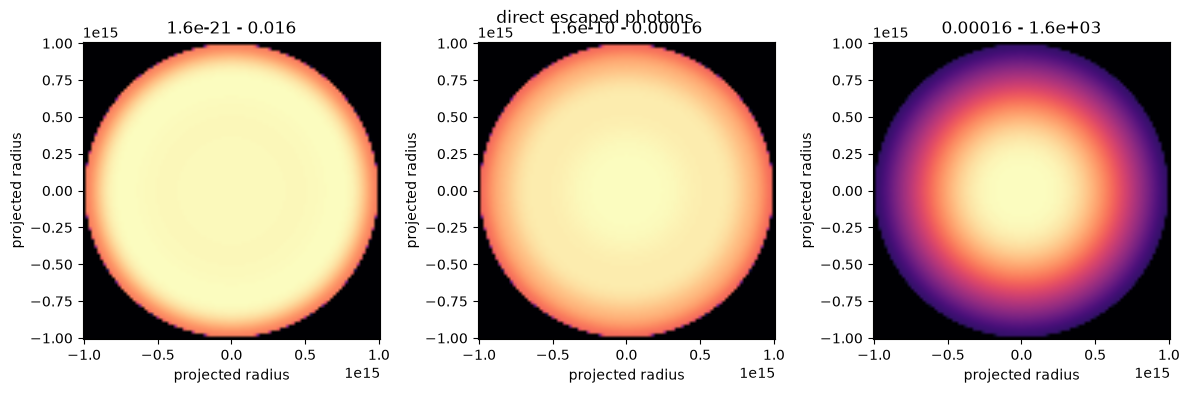

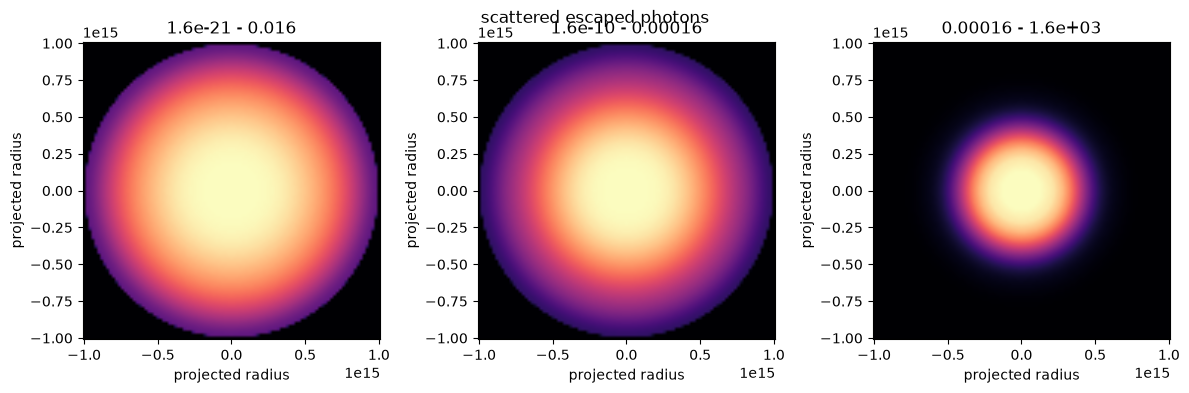

In [12]:
# Diagnostic 5: separate direct and scattered escaped photons.
def packet_subset(result, mask):
    keys = ['energy', 'mu', 'weight', 'position', 'direction', 'n_scatter']
    return {key: result[key][mask] for key in keys if key in result}

direct_mask = escaped['n_scatter'] == 0
scattered_mask = escaped['n_scatter'] > 0
direct_escaped = packet_subset(escaped, direct_mask)
scattered_escaped = packet_subset(escaped, scattered_mask)
print('direct packets:', direct_mask.sum())
print('scattered packets:', scattered_mask.sum())

fig, axes = plot_bands(
    direct_escaped, grid.radius, energy_edges, bands,
    image_size=101, radial_bins=32, kernel_width=4,
)
fig.suptitle('direct escaped photons')
plt.show()

fig, axes = plot_bands(
    scattered_escaped, grid.radius, energy_edges, bands,
    image_size=101, radial_bins=32, kernel_width=4,
)
fig.suptitle('scattered escaped photons')
plt.show()